In [1]:
%load_ext autoreload
%autoreload 2
from plot_utils import callback_twod2

In [2]:
import numpy as np
import anndata
import scanpy as sc

In [3]:
data = anndata.read_h5ad("../../spatial-alignment/examples/synthetic_data.h5ad")
data

AnnData object with n_obs × n_vars = 200 × 30
    obs: 'batch'
    obsm: 'spatial'

In [4]:
data.obsm['spatial'].max()

10.753216234471699

In [5]:
import pandas as pd
refAD = sc.read_h5ad("rep2_spot.h5ad")
queryAD = sc.read_h5ad("rep1_spot.h5ad")
refDF = pd.read_csv("valis_output/ref_cell_positions.csv")
queryDF = pd.read_csv("valis_output/moving_valisOutput.csv")
refDF.index = refDF.Cell_Num.astype(str)
queryDF.index = queryDF.Cell_Num.astype(str)
print(refAD.obs.shape, queryAD.obs.shape, refDF.shape, queryDF.shape)
refAD.obs['New_X'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_X']
refAD.obs['New_Y'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_Y']

queryAD.obs['New_X'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_X']
queryAD.obs['New_Y'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_Y']

refAD.obsm['spatial'] = refAD.obs[['New_X','New_Y']].values
queryAD.obsm['spatial'] = queryAD.obs[['New_X','New_Y']].values

adata1 = refAD.copy()
adata2 = queryAD.copy()
adata1.obs['batch'] = 'rep1'
adata2.obs['batch'] = 'rep2'


(3801, 12) (3184, 12) (3801, 7) (3184, 10)


In [6]:
# Normalize spatial coordinates to 0-10 range for both adata1 and adata2
# Normalize x and y coordinates separately
def normalize_spatial_separately(coords, min_val=0, max_val=500):
    normalized = coords.copy()
    for i in range(2):  # For x (0th column) and y (1st column)
        min_coord = coords[:, i].min()
        max_coord = coords[:, i].max()
        normalized[:, i] = min_val + (coords[:, i] - min_coord) * (max_val - min_val) / (max_coord - min_coord)
    return normalized

#adata1.obsm['spatial'] = normalize_spatial_separately(adata1.obsm['spatial'])
#adata2.obsm['spatial'] = normalize_spatial_separately(adata2.obsm['spatial'])
adata1.obsm['spatial'] = 50+0.5*adata1.obsm['spatial']
adata2.obsm['spatial'] = 50+0.5*adata2.obsm['spatial']

# Verify normalization
print("adata1 spatial range x:", adata1.obsm['spatial'][:, 0].min(), "-", adata1.obsm['spatial'][:, 0].max())
print("adata1 spatial range y:", adata1.obsm['spatial'][:, 1].min(), "-", adata1.obsm['spatial'][:, 1].max())
print("adata2 spatial range x:", adata2.obsm['spatial'][:, 0].min(), "-", adata2.obsm['spatial'][:, 0].max())
print("adata2 spatial range y:", adata2.obsm['spatial'][:, 1].min(), "-", adata2.obsm['spatial'][:, 1].max())




adata1 spatial range x: 50.0 - 495.5
adata1 spatial range y: 50.0 - 549.5
adata2 spatial range x: 17.0940326044 - 508.6478932745
adata2 spatial range y: 40.11910885055 - 540.0153428384999


In [7]:
outAD = sc.concat([adata1, adata2])
outAD.obs['batch'].value_counts()
outAD


/home/adyprat/anaconda3/envs/gpsa2/lib/python3.9/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 6985 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Endothelium_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Epicardium_percentage', 'Fibroblast_percentage', 'Schwan progenitors_percentage', 'Smooth muscle cells_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'batch'
    obsm: 'X_spatial', 'spatial'

In [8]:
outAD.var_names == adata2.var_names , outAD.var_names == adata1.var_names

(array([ True,  True,  True,  True,  True,  True,  True,  True, False,
        False,  True, False, False, False, False,  True, False, False,
        False, False,  True, False, False,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
        False, False,  True,  True, False, False,  True,  True, False,
        False,  True, False, False, False,  True,  True,  True,  True,
         True,  True,  True,  True, False, False,  True,  True,  True,
         True,  True,  True,  True]),
 array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  Tr

In [9]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from gpsa import VariationalGPSA, GPSA
from gpsa import matern12_kernel, rbf_kernel
from gpsa.plotting import callback_twod

device = "cuda:0" if torch.cuda.is_available() else "cpu"

In [10]:

X = outAD.obsm["spatial"]
Y = outAD.X
view_idx = [np.where(outAD.obs.batch.values == ii)[0] for ii in ['rep1', 'rep2']]
n_samples_list = [len(x) for x in view_idx]

x = torch.from_numpy(X).float().clone().to(device)
y = torch.from_numpy(Y).float().clone().to(device)

data_dict = {
    "expression": {
        "spatial_coords": x,
        "outputs": y,
        "n_samples_list": n_samples_list,
    }
}
n_samples_list, view_idx

([3801, 3184],
 [array([   0,    1,    2, ..., 3798, 3799, 3800]),
  array([3801, 3802, 3803, ..., 6982, 6983, 6984])])

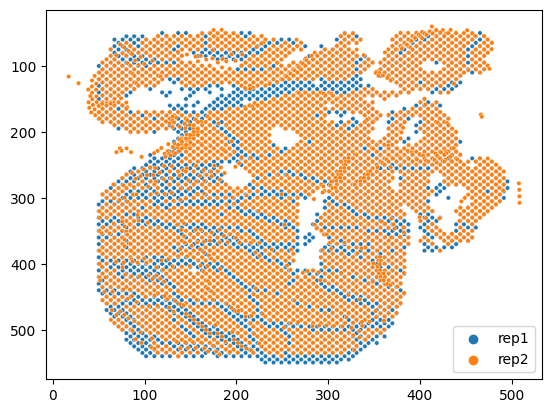

In [11]:
sns.scatterplot(x=outAD.obsm["spatial"][:,0],y=outAD.obsm["spatial"][:,1],hue=outAD.obs['batch'].values,s=10)
plt.gca().invert_yaxis()




In [12]:
print(torch.cuda.is_available())
print(torch.cuda.current_device())
print(torch.cuda.get_device_name(torch.cuda.current_device()))

True
0
NVIDIA TITAN RTX


In [13]:
# import torch
# X = data.obsm["spatial"]
# Y = data.X
# view_idx = [np.where(data.obs.batch.values == ii)[0] for ii in range(2)]
# n_samples_list = [len(x) for x in view_idx]

# x = torch.from_numpy(X).float().clone().to(device)
# y = torch.from_numpy(Y).float().clone().to(device)

# data_dict = {
#     "expression": {
#         "spatial_coords": x,
#         "outputs": y,
#         "n_samples_list": n_samples_list,
#     }
# }


In [14]:


N_SPATIAL_DIMS = 2
N_VIEWS = 2
M_G = 50
M_X_PER_VIEW = 50
N_OUTPUTS = 5
FIXED_VIEW_IDX = 0
N_LATENT_GPS = {"expression": None}

N_EPOCHS = 1000
PRINT_EVERY = 100

model = VariationalGPSA(
    data_dict,
    n_spatial_dims=N_SPATIAL_DIMS,
    m_X_per_view=M_X_PER_VIEW,
    m_G=M_G,
    data_init=True,
    minmax_init=False,
    grid_init=False,
    n_latent_gps=N_LATENT_GPS,
    mean_function="identity_fixed",
    kernel_func_warp=rbf_kernel,
    kernel_func_data=rbf_kernel,
    fixed_view_idx=FIXED_VIEW_IDX,
).to(device)

view_idx, Ns, _, _ = model.create_view_idx_dict(data_dict)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

In [15]:
from plot_utils import callback_twod2

/home/adyprat/anaconda3/envs/gpsa2/lib/python3.9/site-packages/gpsa/models/vgpsa.py:257: UserWarning: torch.cholesky is deprecated in favor of torch.linalg.cholesky and will be removed in a future PyTorch release.
L = torch.cholesky(A)
should be replaced with
L = torch.linalg.cholesky(A)
and
U = torch.cholesky(A, upper=True)
should be replaced with
U = torch.linalg.cholesky(A).mH
This transform will produce equivalent results for all valid (symmetric positive definite) inputs. (Triggered internally at ../aten/src/ATen/native/BatchLinearAlgebra.cpp:1691.)
  self.curr_Omega_tril_list = torch.cholesky(curr_Omega_G)


Iter: 100        LL -8.964e+06


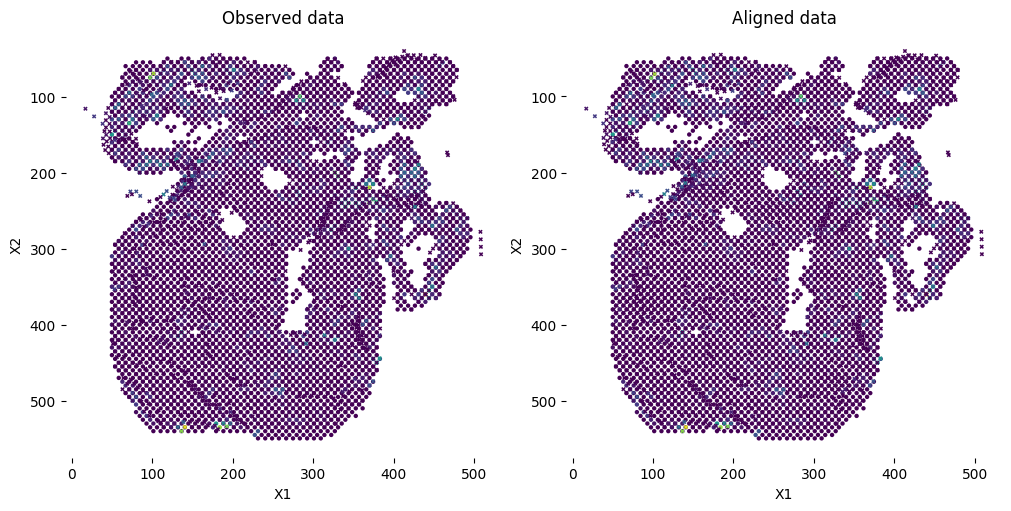

Iter: 200        LL -4.422e+06


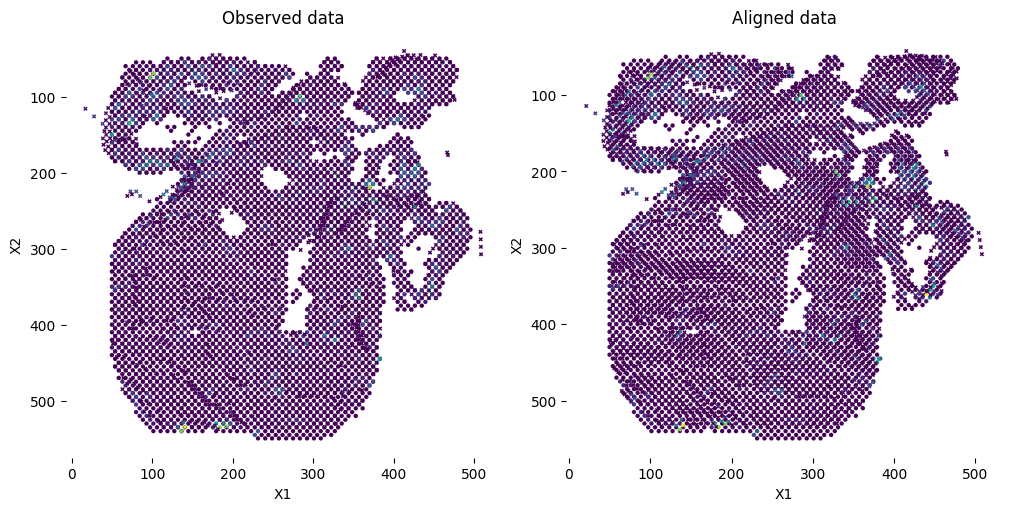

Iter: 300        LL -2.753e+06


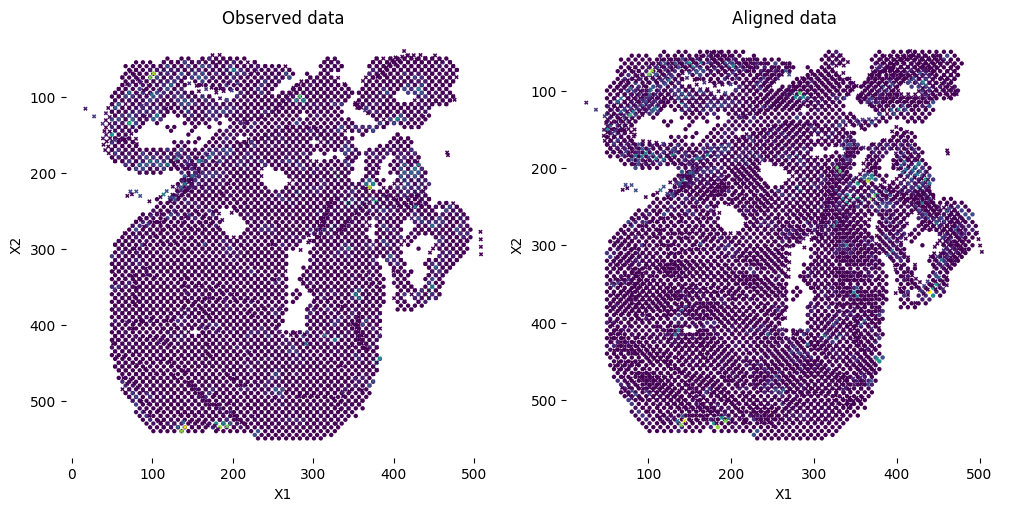

Iter: 400        LL -2.229e+06


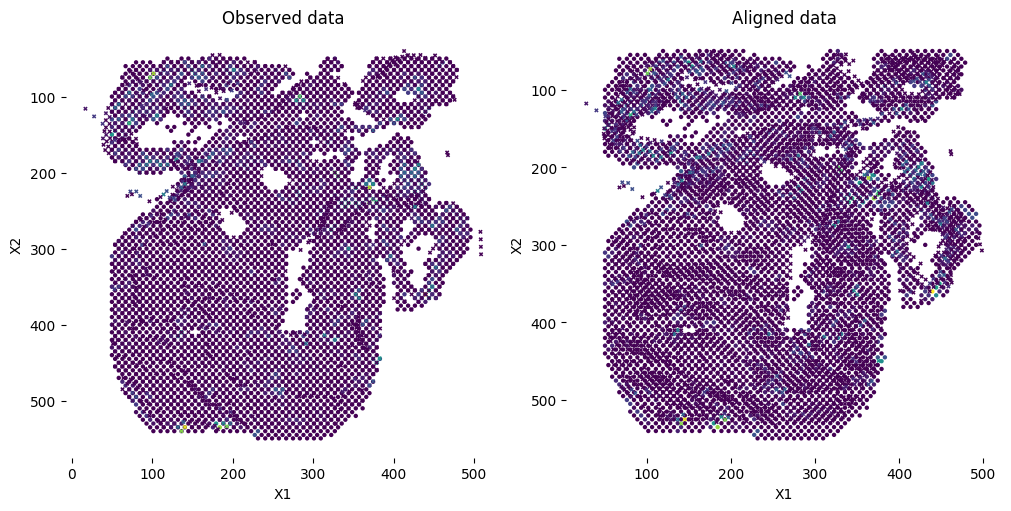

Iter: 500        LL -1.946e+06


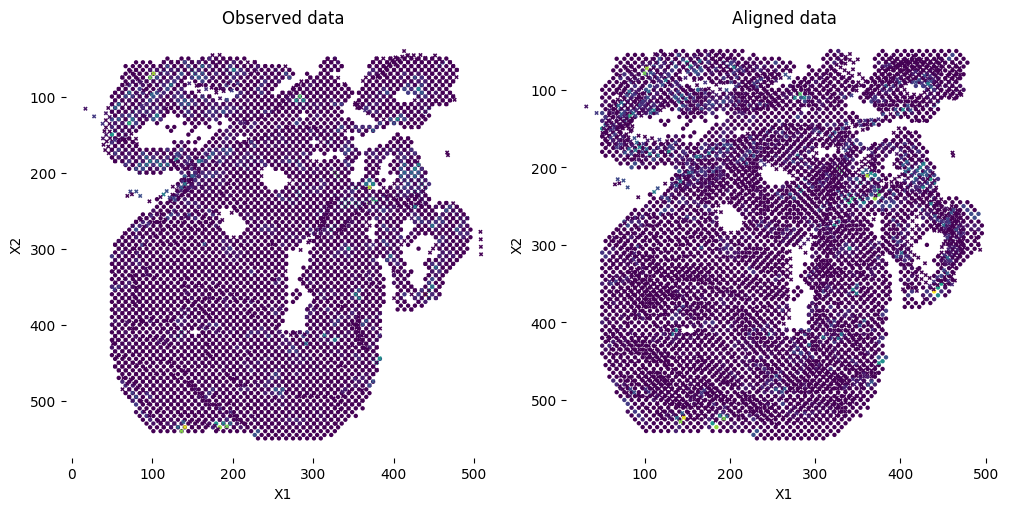

Iter: 600        LL -1.775e+06


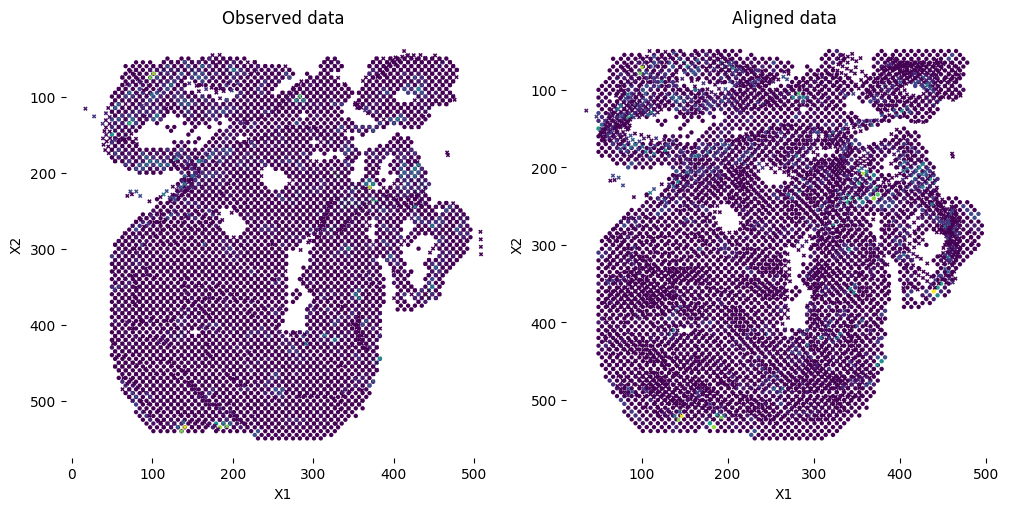

Iter: 700        LL -1.665e+06


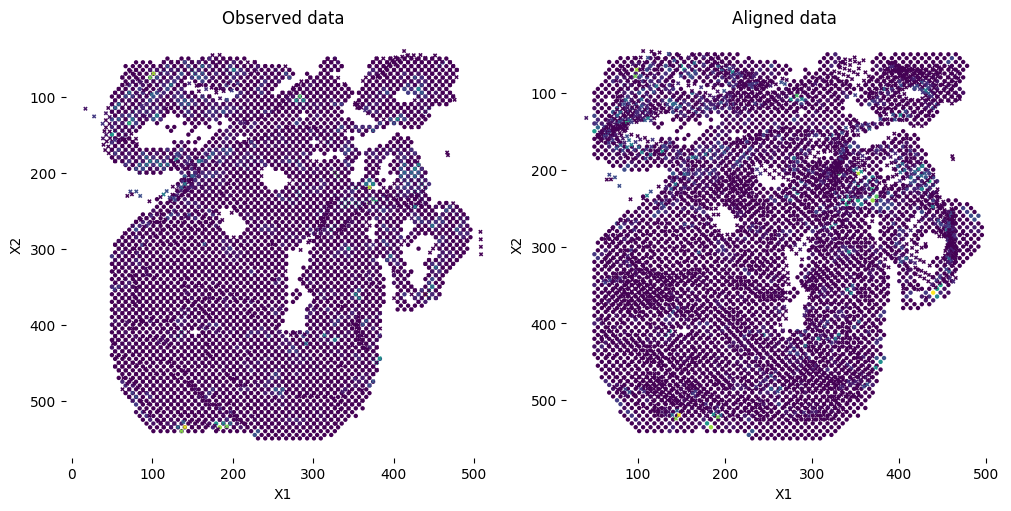

Iter: 800        LL -1.589e+06


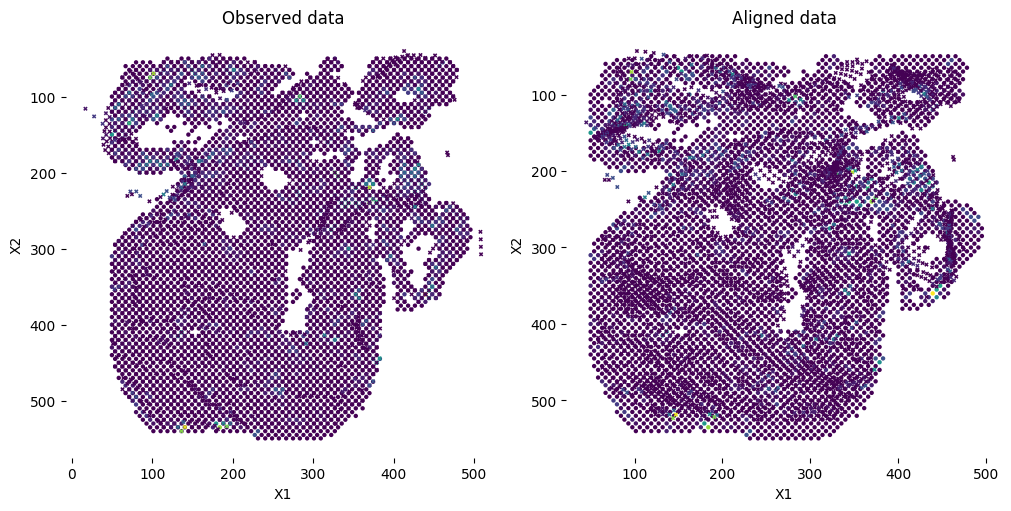

Iter: 900        LL -1.533e+06


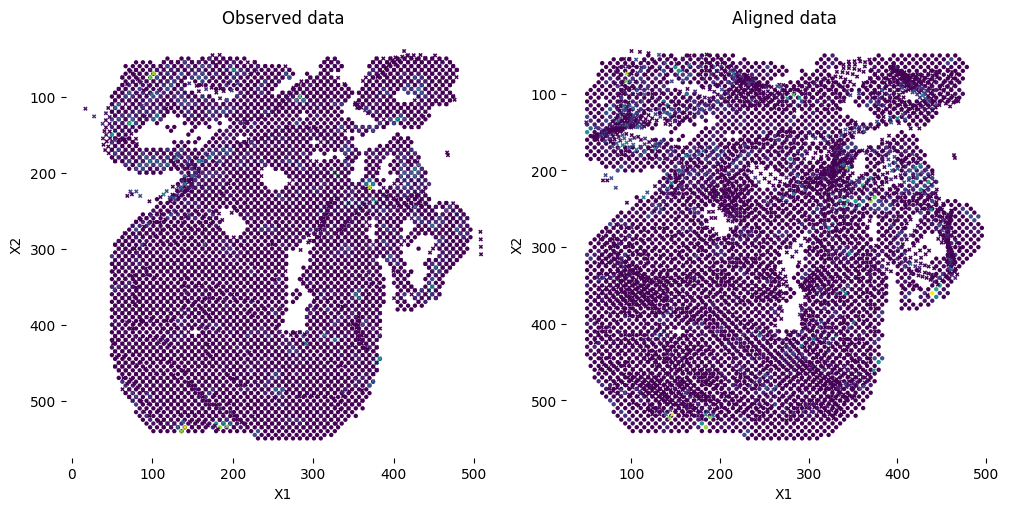

Done!


In [16]:
def train(model, loss_fn, optimizer):
    model.train()

    # Forward pass
    G_means, G_samples, F_latent_samples, F_samples = model.forward(
        {"expression": x}, view_idx=view_idx, Ns=Ns, S=5
    )

    # Compute loss
    loss = loss_fn(data_dict, F_samples)

    # Compute gradients and take optimizer step
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item()


# Set up figure.
fig = plt.figure(figsize=(10, 5), facecolor="white", constrained_layout=True)
data_expression_ax = fig.add_subplot(121, frameon=False)
latent_expression_ax = fig.add_subplot(122, frameon=False)
#plt.show(block=False)

for t in range(N_EPOCHS):
    loss = train(model, model.loss_fn, optimizer)

    if t>0 and t % PRINT_EVERY == 0:
        print("Iter: {0:<10} LL {1:1.3e}".format(t, -loss))
        G_means, _, _, _ = model.forward({"expression": x}, view_idx=view_idx, Ns=Ns)

        callback_twod2(
            model,
            X,
            Y,
            data_expression_ax=data_expression_ax,
            latent_expression_ax=latent_expression_ax,
            X_aligned=G_means,
            s=10,
        )
        #plt.gca().invert_yaxis()
        plt.draw()
        plt.pause(1 / 60.0)

print("Done!")

plt.close()

In [17]:
adata1.shape, adata2.shape

((3801, 67), (3184, 67))

In [19]:
outCoords = G_means['expression'].detach().cpu().numpy()
outCoords.shape



(6985, 2)

In [21]:

n_samples_per_view = adata1.shape[0]

view1_aligned_coords = outCoords[:n_samples_per_view]
view2_aligned_coords = outCoords[n_samples_per_view:]


In [22]:
adata2.obs['new_X'] = view2_aligned_coords[:,0]
adata2.obs['new_Y'] = view2_aligned_coords[:,1]

adata1.obs['new_X'] = view1_aligned_coords[:,0]
adata1.obs['new_Y'] = view1_aligned_coords[:,1]

<AxesSubplot:xlabel='new_X', ylabel='new_Y'>

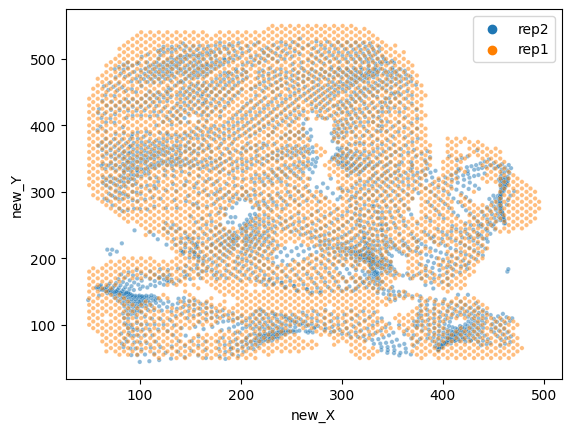

In [26]:
sns.scatterplot(x=adata2.obs['new_X'],y=adata2.obs['new_Y'],hue=adata2.obs['batch'].values,s=10, alpha=0.5)
sns.scatterplot(x=adata1.obs['new_X'],y=adata1.obs['new_Y'],hue=adata1.obs['batch'].values,palette='Set1_r',s=10, alpha=0.5)

In [24]:
adata2.write_h5ad('heart_spot_moving_gpsa.h5ad')
adata1.write_h5ad('heart_spot_ref_gpsa.h5ad')
